
## CELL 1 — Config

In [1]:
"""
NOTEBOOK 2A.2 - Cross-Attention Map (Komponen 2 XAI)
Fase 2A IndoMeme-XAI

Atribusi gambar via ICAM Stream 1 (text-to-image cross-attention).
Output: 14x14 attention map per sample, dipakai utk:
  - Visualisasi case study (Fase 2C)
  - ROAR masking di gambar (Fase 2B)
"""

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"
CKPT_PATH    = Path("/kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt") 
OUTPUT_DIR = Path("/kaggle/working/xai_2A2_cross_attention")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    exp_id           = "2A.2_cross_attention_map",
    seed             = 42,

    text_model_name  = "indolem/indobertweet-base-uncased",
    image_model_name = "google/vit-base-patch16-224-in21k",
    freeze_n_layers  = 4,
    topic_emb_dim    = 32,
    head_hidden      = 256,
    dropout          = 0.3,
    icam_num_heads   = 8,
    icam_dropout     = 0.1,
    supcon_proj_hidden  = 128,
    supcon_proj_out     = 128,
    max_seq_len      = 128,

    batch_size       = 16,
    n_viz_samples    = 8,           # 2 TP + 2 TN + 2 FP + 2 FN

    grid_size        = 14,          # ViT-Base patch16 224 -> 14x14 grid
    img_size         = 224,
)

print(f"Experiment: {CONFIG['exp_id']}")
print(f"Checkpoint: {CKPT_PATH}")

Experiment: 2A.2_cross_attention_map
Checkpoint: /kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt


## CELL 2 — Imports

In [2]:
import os, json, random, time, math, re, unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel, ViTImageProcessor, ViTModel
from tqdm.auto import tqdm

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


## CELL 3 — Slang Dictionary

In [3]:
SLANG_DICT = {
    "gw":"saya","gue":"saya","gua":"saya","guwe":"saya",
    "lu":"kamu","lo":"kamu","loe":"kamu","elo":"kamu","elu":"kamu",
    "ane":"saya","ente":"kamu","agan":"kamu","sis":"kakak",
    "bro":"kawan","bray":"kawan","bre":"kawan","cuy":"kawan",
    "klian":"kalian","kmu":"kamu","kamuh":"kamu",
    "aq":"aku","akoh":"aku","akuh":"aku",
    "gak":"tidak","ga":"tidak","gk":"tidak","nggak":"tidak",
    "ngga":"tidak","ngk":"tidak","kgk":"tidak","tdk":"tidak",
    "engga":"tidak","enggak":"tidak","kga":"tidak",
    "yg":"yang","dgn":"dengan","dg":"dengan","krn":"karena",
    "krna":"karena","utk":"untuk","tp":"tapi","tpi":"tapi",
    "klo":"kalau","klau":"kalau","kl":"kalau","klu":"kalau",
    "spy":"supaya","ato":"atau",
    "bgt":"banget","bgtt":"banget","bngt":"banget",
    "bnr":"benar","bener":"benar",
    "emg":"memang","emang":"memang","mmg":"memang",
    "skrg":"sekarang","skrng":"sekarang",
    "td":"tadi","tdi":"tadi","bsk":"besok",
    "knp":"kenapa","gmn":"bagaimana","gimana":"bagaimana",
    "gmana":"bagaimana","kyk":"seperti","kayak":"seperti","kek":"seperti",
    "udh":"sudah","udah":"sudah","uda":"sudah","dah":"sudah",
    "blm":"belum","blom":"belum",
    "lg":"lagi","lgi":"lagi","msh":"masih","msi":"masih",
    "jd":"jadi","jdi":"jadi",
    "tau":"tahu","taw":"tahu","tw":"tahu",
    "liat":"lihat","ngeliat":"melihat","denger":"dengar",
    "ngomong":"bicara","blng":"bilang","bilg":"bilang",
    "aja":"saja","doang":"saja","doank":"saja",
    "sih":"","deh":"","dong":"","kok":"","lah":"",
    "loh":"","lho":"","yah":"",
    "iy":"iya","iyaa":"iya","iye":"iya","yup":"iya","yoi":"iya",
    "org":"orang","orng":"orang","orgnya":"orangnya",
    "dr":"dari","dri":"dari","kpd":"kepada",
    "thd":"terhadap","ttg":"tentang",
    "abis":"habis","trs":"terus","trus":"terus",
    "tmn":"teman","temen":"teman","tman":"teman",
    "rmh":"rumah","kntr":"kantor","krj":"kerja",
    "ank":"anak","indo":"indonesia",
    "cwo":"cowok","cwe":"cewek","cwok":"cowok","cwek":"cewek",
    "wkwk":"haha","wkwkwk":"haha","wkwkwkwk":"haha","wkwkwkwkwk":"haha",
    "hahaha":"haha","hahahaha":"haha",
    "hehehe":"hehe","hehehehe":"hehe",
    "anjir":"anjing","anjay":"anjing","anjrit":"anjing",
    "anjr":"anjing","anying":"anjing","njir":"anjing",
    "bgsd":"bangsat","bgst":"bangsat",
    "bjir":"anjing","bjg":"bajingan",
    "kntl":"kontol","mmk":"memek","tai":"tahi",
}

## CELL 4 — clean_ocr

In [4]:
URL_PATTERN     = re.compile(r"(https?://\S+|www\.\S+|\S+\.(?:com|co\.id|net|org|id|tv|me)\b\S*)", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@\w+")
HASHTAG_PATTERN = re.compile(r"#(\w+)")
ALLOWED_PUNCT   = re.compile(r"[^\w\s\.,!?\-'\"]+", re.UNICODE)
MULTI_SPACE     = re.compile(r"\s+")

def _normalize_unicode(t): return unicodedata.normalize("NFKC", t)

def _normalize_slang(text, slang_dict=SLANG_DICT):
    out = []
    for tok in text.split():
        prefix, suffix, core = "", "", tok
        while core and not core[0].isalnum(): prefix += core[0]; core = core[1:]
        while core and not core[-1].isalnum(): suffix = core[-1] + suffix; core = core[:-1]
        out.append(f"{prefix}{slang_dict.get(core.lower(), core)}{suffix}")
    return " ".join(out)

def clean_ocr(text):
    if text is None: return ""
    if isinstance(text, float) and pd.isna(text): return ""
    text = _normalize_unicode(str(text)).lower()
    text = URL_PATTERN.sub(" ", text)
    text = MENTION_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(r"\1", text)
    text = ALLOWED_PUNCT.sub(" ", text)
    text = _normalize_slang(text)
    return MULTI_SPACE.sub(" ", text).strip()

SEP_TOKEN = "[SEP]"
def _safe_str(x):
    if x is None: return ""
    if isinstance(x, float) and pd.isna(x): return ""
    return str(x).strip()

def format_input(topic, caption, ocr_cleaned, sep=SEP_TOKEN):
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        topic_str = "unknown"
    elif isinstance(topic, (list, tuple, set)):
        items = sorted({str(t).lower().strip() for t in topic if t})
        topic_str = ",".join(items) if items else "unknown"
    else:
        topic_str = str(topic).lower().strip() or "unknown"
    return f"[{topic_str}] {_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()

## CELL 5 — Load Data + Topic Encoding

In [5]:
df = pd.read_csv(CSV_PATH)
LABEL_MAP = {"not hate": 0, "hate": 1}
df["label"] = df["hate_final"].map(LABEL_MAP)
df["ocr_cleaned"] = df["ocr"].apply(clean_ocr)
df["text_input"]  = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"]), axis=1)

def resolve_image_path(row):
    raw = row.get("local_image_path") or row.get("image_path")
    if raw is None or (isinstance(raw, float) and pd.isna(raw)): return None
    fname = Path(str(raw).replace("\\","/")).name
    return str(IMG_DIR / row["split"] / fname)
df["full_image_path"] = df.apply(resolve_image_path, axis=1)

TOPIC_LIST = ["political","national origin","individual","institutions",
              "gender","religion","social sub-groups","unknown"]
TOPIC2IDX = {t: i for i, t in enumerate(TOPIC_LIST)}
N_TOPICS  = len(TOPIC_LIST)

def topic_to_multihot(topic):
    vec = np.zeros(N_TOPICS, dtype=np.float32)
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        vec[TOPIC2IDX["unknown"]] = 1.0; return vec
    parts = [p.strip().lower() for p in str(topic).split(",") if p.strip()]
    found = False
    for p in parts:
        if p in TOPIC2IDX: vec[TOPIC2IDX[p]] = 1.0; found = True
    if not found: vec[TOPIC2IDX["unknown"]] = 1.0
    return vec

df["topic_multihot"] = df["topic"].apply(topic_to_multihot)
df_test = df[df["split"] == "test"].copy().reset_index(drop=True)
print(f"Test samples: {len(df_test)}")

Test samples: 1005


## CELL 6 — Tokenizer + Transforms

In [6]:
tokenizer       = AutoTokenizer.from_pretrained(CONFIG["text_model_name"])
image_processor = ViTImageProcessor.from_pretrained(CONFIG["image_model_name"])

IMG_MEAN = image_processor.image_mean
IMG_STD  = image_processor.image_std

EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])
print(f"Image: size={CONFIG['img_size']}, grid={CONFIG['grid_size']}x{CONFIG['grid_size']}")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Image: size=224, grid=14x14


## CELL 7 — Dataset Class (

In [7]:
class IndoMemeDataset(Dataset):
    def __init__(self, df_split, tokenizer, transform, max_seq_len=128):
        self.df = df_split.reset_index(drop=True)
        self.tokenizer = tokenizer; self.transform = transform; self.max_seq_len = max_seq_len

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["full_image_path"]).convert("RGB")
        img_tensor = self.transform(img)
        enc = self.tokenizer(row["text_input"], padding="max_length", truncation=True,
                             max_length=self.max_seq_len, return_tensors="pt")
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "pixel_values":   img_tensor,
            "topic":          torch.from_numpy(row["topic_multihot"]),
            "label":          torch.tensor(int(row["label"]), dtype=torch.long),
            "idx":            int(row["idx"]),
            "image_path":     row["full_image_path"],
        }

ds_test = IndoMemeDataset(df_test, tokenizer, EVAL_TRANSFORM, CONFIG["max_seq_len"])
dl_test = DataLoader(ds_test, batch_size=CONFIG["batch_size"], shuffle=False,
                     num_workers=2, pin_memory=True, collate_fn=lambda b: {
                         k: torch.stack([d[k] for d in b]) if isinstance(b[0][k], torch.Tensor)
                            else [d[k] for d in b]
                         for k in b[0]
                     })
print(f"Loader: {len(dl_test)} batches of {CONFIG['batch_size']}")

Loader: 63 batches of 16


## CELL 8 — ICAM dengan save_attn Aktif

In [8]:
class ICAMFusion(nn.Module):
    def __init__(self, hidden_dim=768, num_heads=8, dropout=0.1):
        super().__init__()
        self.t2i_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.i2t_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.gate_relevant    = nn.Linear(2 * hidden_dim, hidden_dim)
        self.gate_incongruent = nn.Linear(2 * hidden_dim, hidden_dim)
        self.fusion_proj = nn.Linear(hidden_dim, hidden_dim)
        self.layer_norm  = nn.LayerNorm(hidden_dim)

        # XAI buffers
        self.save_attn        = False
        self.last_t2i_attn    = None
        self.last_i2t_attn    = None
        self.last_incongruity = None
        self.last_g1          = None
        self.last_g2          = None

    def forward(self, text_h, image_h, text_mask=None):
        text_kpm = (~text_mask.bool()) if text_mask is not None else None

        t2i_out, t2i_w = self.t2i_attn(
            query=text_h, key=image_h, value=image_h,
            key_padding_mask=None,
            need_weights=self.save_attn, average_attn_weights=True,
        )
        i2t_out, i2t_w = self.i2t_attn(
            query=image_h, key=text_h, value=text_h,
            key_padding_mask=text_kpm,
            need_weights=self.save_attn, average_attn_weights=True,
        )
        h_image_pooled = i2t_out.mean(dim=1)

        text_norm  = F.normalize(text_h,  dim=-1)
        image_norm = F.normalize(image_h, dim=-1)
        sim         = torch.bmm(text_norm, image_norm.transpose(1, 2))
        incongruity = 1.0 - sim.abs()
        inc_w       = F.softmax(incongruity, dim=-1)
        h_inc       = torch.bmm(inc_w, image_h)

        if text_mask is not None:
            m = text_mask.unsqueeze(-1).float()
            h_inc_pooled = (h_inc * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
        else:
            h_inc_pooled = h_inc.mean(dim=1)

        h_text = text_h[:, 0]
        g1 = torch.sigmoid(self.gate_relevant(   torch.cat([h_text, h_image_pooled], dim=-1)))
        g2 = torch.sigmoid(self.gate_incongruent(torch.cat([h_text, h_inc_pooled  ], dim=-1)))

        fused   = h_text + g1 * h_image_pooled + g2 * h_inc_pooled
        h_fused = self.layer_norm(self.fusion_proj(fused))

        if self.save_attn:
            self.last_t2i_attn    = t2i_w.detach() if t2i_w is not None else None
            self.last_i2t_attn    = i2t_w.detach() if i2t_w is not None else None
            self.last_incongruity = incongruity.detach()
            self.last_g1          = g1.detach()
            self.last_g2          = g2.detach()

        return h_fused, g1.mean().item(), g2.mean().item()

## CELL 9 — Full Model (return 4-tuple, kompatibel state_dict 1B.9)

In [9]:
class ICAMHateModelSupCon(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.text_encoder  = AutoModel.from_pretrained(cfg["text_model_name"])
        self.image_encoder = ViTModel.from_pretrained(cfg["image_model_name"])
        for p in self.text_encoder.parameters():  p.requires_grad = False
        for p in self.image_encoder.parameters(): p.requires_grad = False

        hidden = self.text_encoder.config.hidden_size
        self.icam = ICAMFusion(hidden_dim=hidden, num_heads=cfg["icam_num_heads"], dropout=cfg["icam_dropout"])
        self.supcon_proj = nn.Sequential(
            nn.Linear(hidden, cfg["supcon_proj_hidden"]),
            nn.ReLU(),
            nn.Linear(cfg["supcon_proj_hidden"], cfg["supcon_proj_out"]),
        )
        self.topic_proj = nn.Sequential(nn.Linear(N_TOPICS, cfg["topic_emb_dim"]), nn.GELU())
        head_in = hidden + cfg["topic_emb_dim"]
        self.head = nn.Sequential(
            nn.Linear(head_in, cfg["head_hidden"]), nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(cfg["head_hidden"], 2),
        )

    def forward(self, input_ids, attention_mask, pixel_values, topic):
        t_out = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        i_out = self.image_encoder(pixel_values=pixel_values)
        h_fused, g1m, g2m = self.icam(t_out.last_hidden_state, i_out.last_hidden_state, attention_mask)
        supcon_features = F.normalize(self.supcon_proj(h_fused), dim=-1)
        topic_emb = self.topic_proj(topic)
        logits    = self.head(torch.cat([h_fused, topic_emb], dim=-1))
        return logits, supcon_features, g1m, g2m

## CELL 10 — Load Frozen Checkpoint

In [10]:
model = ICAMHateModelSupCon(CONFIG).to(DEVICE)

ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
state = ckpt["state_dict"] if (isinstance(ckpt, dict) and "state_dict" in ckpt) else ckpt
print(f"Checkpoint epoch: {ckpt.get('epoch', '?') if isinstance(ckpt, dict) else '?'}")

missing, unexpected = model.load_state_dict(state, strict=False)
print(f"Missing keys: {len(missing)}, Unexpected: {len(unexpected)}")

for p in model.parameters(): p.requires_grad = False
model.eval()

# AKTIFKAN penyimpanan attention
model.icam.save_attn = True
print(f"save_attn = {model.icam.save_attn}")

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Checkpoint epoch: 15
Missing keys: 0, Unexpected: 0
save_attn = True


## CELL 11 — Cross-Attention Extraction Function

In [11]:
@torch.no_grad()
def extract_cross_attn_batch(model, batch):
    """
    Extract Cross-Attention Map dari ICAM Stream 1 (text-to-image).

    Pipeline:
      1. Forward pass utk update model.icam.last_t2i_attn -> [B, T_text=128, P_image=197]
      2. Average atas T_text dgn attention mask (skip padding tokens)
      3. Drop CLS image token (posisi 0) -> [B, 196]
      4. Reshape ke 14x14 grid -> [B, 14, 14]

    Returns:
      maps_14x14 : np.ndarray [B, 14, 14] - attention map per sample
      preds      : np.ndarray [B] - predicted class
      pred_probs : np.ndarray [B] - softmax prob of predicted class
    """
    input_ids      = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    pixel_values   = batch["pixel_values"].to(DEVICE)
    topic          = batch["topic"].to(DEVICE)

    with autocast(device_type="cuda"):
        logits, _, _, _ = model(input_ids, attention_mask, pixel_values, topic)

    # t2i attention: [B, T_text, P_image]
    t2i = model.icam.last_t2i_attn.float()                          # to fp32

    # Average atas T_text dgn mask (skip padding)
    mask_f = attention_mask.float().unsqueeze(-1)                   # [B, T, 1]
    t2i_avg = (t2i * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1.0)   # [B, P_image]

    # Drop CLS posisi 0
    t2i_patches = t2i_avg[:, 1:]                                    # [B, 196]

    # Reshape 14x14
    G = CONFIG["grid_size"]
    maps_14x14 = t2i_patches.reshape(-1, G, G)                      # [B, 14, 14]

    # Predictions
    probs = F.softmax(logits.float(), dim=-1)
    preds = probs.argmax(dim=-1)
    pred_probs = probs.gather(1, preds.unsqueeze(1)).squeeze(1)

    return (maps_14x14.cpu().numpy(),
            preds.cpu().numpy(),
            pred_probs.cpu().numpy())

## CELL 12 — Run on Full Test Set

In [12]:
all_maps, all_preds, all_probs, all_labels, all_idxs, all_paths = [], [], [], [], [], []

t0 = time.time()
for batch in tqdm(dl_test, desc="cross-attn extraction"):
    maps_b, preds_b, probs_b = extract_cross_attn_batch(model, batch)
    all_maps.append(maps_b)
    all_preds.append(preds_b)
    all_probs.append(probs_b)
    all_labels.extend(batch["label"].tolist())   # label tetap tensor -> .tolist() OK
    all_idxs.extend(batch["idx"])                # idx sudah list dari collate_fn
    all_paths.extend(batch["image_path"])        # image_path sudah list

all_maps   = np.concatenate(all_maps,   axis=0)
all_preds  = np.concatenate(all_preds,  axis=0)
all_probs  = np.concatenate(all_probs,  axis=0)
all_labels = np.array(all_labels, dtype=np.int8)
all_idxs   = np.array(all_idxs,   dtype=np.int64)

elapsed = time.time() - t0
print(f"\nDone. {len(all_maps)} samples in {elapsed/60:.1f} min")
print(f"Maps shape: {all_maps.shape}  (size: {all_maps.nbytes/1e6:.2f} MB)")

cross-attn extraction:   0%|          | 0/63 [00:00<?, ?it/s]


Done. 1005 samples in 0.4 min
Maps shape: (1005, 14, 14)  (size: 0.79 MB)


## CELL 13 — Save Artifacts

In [13]:
np.savez_compressed(
    OUTPUT_DIR / "cross_attn_maps.npz",
    maps_14x14=all_maps.astype(np.float32),
    pred_class=all_preds.astype(np.int8),
    pred_prob=all_probs.astype(np.float32),
    true_label=all_labels,
    idxs=all_idxs,
)

# Path mapping (untuk load image saat visualisasi/ROAR)
with open(OUTPUT_DIR / "image_paths.json", "w") as f:
    json.dump([{"idx": int(i), "path": p} for i, p in zip(all_idxs, all_paths)], f)

print(f"Saved: cross_attn_maps.npz  ({all_maps.nbytes/1e6:.2f} MB)")
print(f"Saved: image_paths.json")

Saved: cross_attn_maps.npz  (0.79 MB)
Saved: image_paths.json


## CELL 14 — Sanity Checks

In [14]:
print(f"\n{'='*72}\nCROSS-ATTENTION SANITY CHECKS\n{'='*72}")

acc = (all_preds == all_labels).mean()
print(f"Test accuracy (sanity check, harus ~0.815): {acc:.4f}")

# Statistik per-map
print(f"\nMap stats (per sample, 14x14 = 196 patches):")
print(f"  Mean attention   : {all_maps.mean():.5f}")
print(f"  Std (across maps): {all_maps.std():.5f}")
print(f"  Min / Max        : {all_maps.min():.5f} / {all_maps.max():.5f}")

# Konsentrasi attention: top-K patch contribution
flat = all_maps.reshape(len(all_maps), -1)                # [N, 196]
flat_sorted = -np.sort(-flat, axis=1)                     # descending
top10_share = flat_sorted[:, :10].sum(axis=1)             # share top-10 patches
top20_share = flat_sorted[:, :20].sum(axis=1)
print(f"\nKonsentrasi attention (rata-rata per sampel):")
print(f"  Top-10 patches  : {top10_share.mean()*100:.1f}%  (uniform = {10/196*100:.1f}%)")
print(f"  Top-20 patches  : {top20_share.mean()*100:.1f}%  (uniform = {20/196*100:.1f}%)")

# Per-class summary
for cls, name in [(0, "not_hate"), (1, "hate")]:
    sel = (all_preds == cls)
    if sel.sum() > 0:
        print(f"\n  Pred={name} (n={sel.sum()}): "
              f"mean={all_maps[sel].mean():.5f}  top10_share={flat_sorted[sel, :10].sum(axis=1).mean()*100:.1f}%")


CROSS-ATTENTION SANITY CHECKS
Test accuracy (sanity check, harus ~0.815): 0.8149

Map stats (per sample, 14x14 = 196 patches):
  Mean attention   : 0.00508
  Std (across maps): 0.00005
  Min / Max        : 0.00477 / 0.00536

Konsentrasi attention (rata-rata per sampel):
  Top-10 patches  : 5.2%  (uniform = 5.1%)
  Top-20 patches  : 10.3%  (uniform = 10.2%)

  Pred=not_hate (n=648): mean=0.00508  top10_share=5.2%

  Pred=hate (n=357): mean=0.00508  top10_share=5.2%


## CELL 15 — Visualisasi: Helper Function

In [15]:
def overlay_attention(img_pil, attn_14x14, alpha=0.5, cmap_name="jet"):
    """Overlay attention heatmap (14x14) di atas gambar PIL."""
    # Upsample ke ukuran image asli
    H, W = CONFIG["img_size"], CONFIG["img_size"]
    attn_t = torch.from_numpy(attn_14x14).float().unsqueeze(0).unsqueeze(0)  # [1,1,14,14]
    attn_up = F.interpolate(attn_t, size=(H, W), mode="bilinear", align_corners=False)
    attn_np = attn_up.squeeze().numpy()

    # Normalize to [0,1]
    a_min, a_max = attn_np.min(), attn_np.max()
    attn_norm = (attn_np - a_min) / (a_max - a_min + 1e-8)

    # Apply colormap
    cmap = cm.get_cmap(cmap_name)
    heat = cmap(attn_norm)[..., :3]                                          # [H, W, 3]

    # Resize image ke H,W lalu blend
    img_resized = img_pil.resize((W, H))
    img_arr = np.asarray(img_resized).astype(np.float32) / 255.0
    if img_arr.ndim == 2:                                                    # grayscale safety
        img_arr = np.stack([img_arr]*3, axis=-1)
    if img_arr.shape[-1] == 4:                                               # drop alpha
        img_arr = img_arr[..., :3]

    blended = (1 - alpha) * img_arr + alpha * heat
    return np.clip(blended, 0, 1), attn_norm

## CELL 16 — Visualisasi 8 Sampel Representatif

/tmp/ipykernel_23/168114787.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


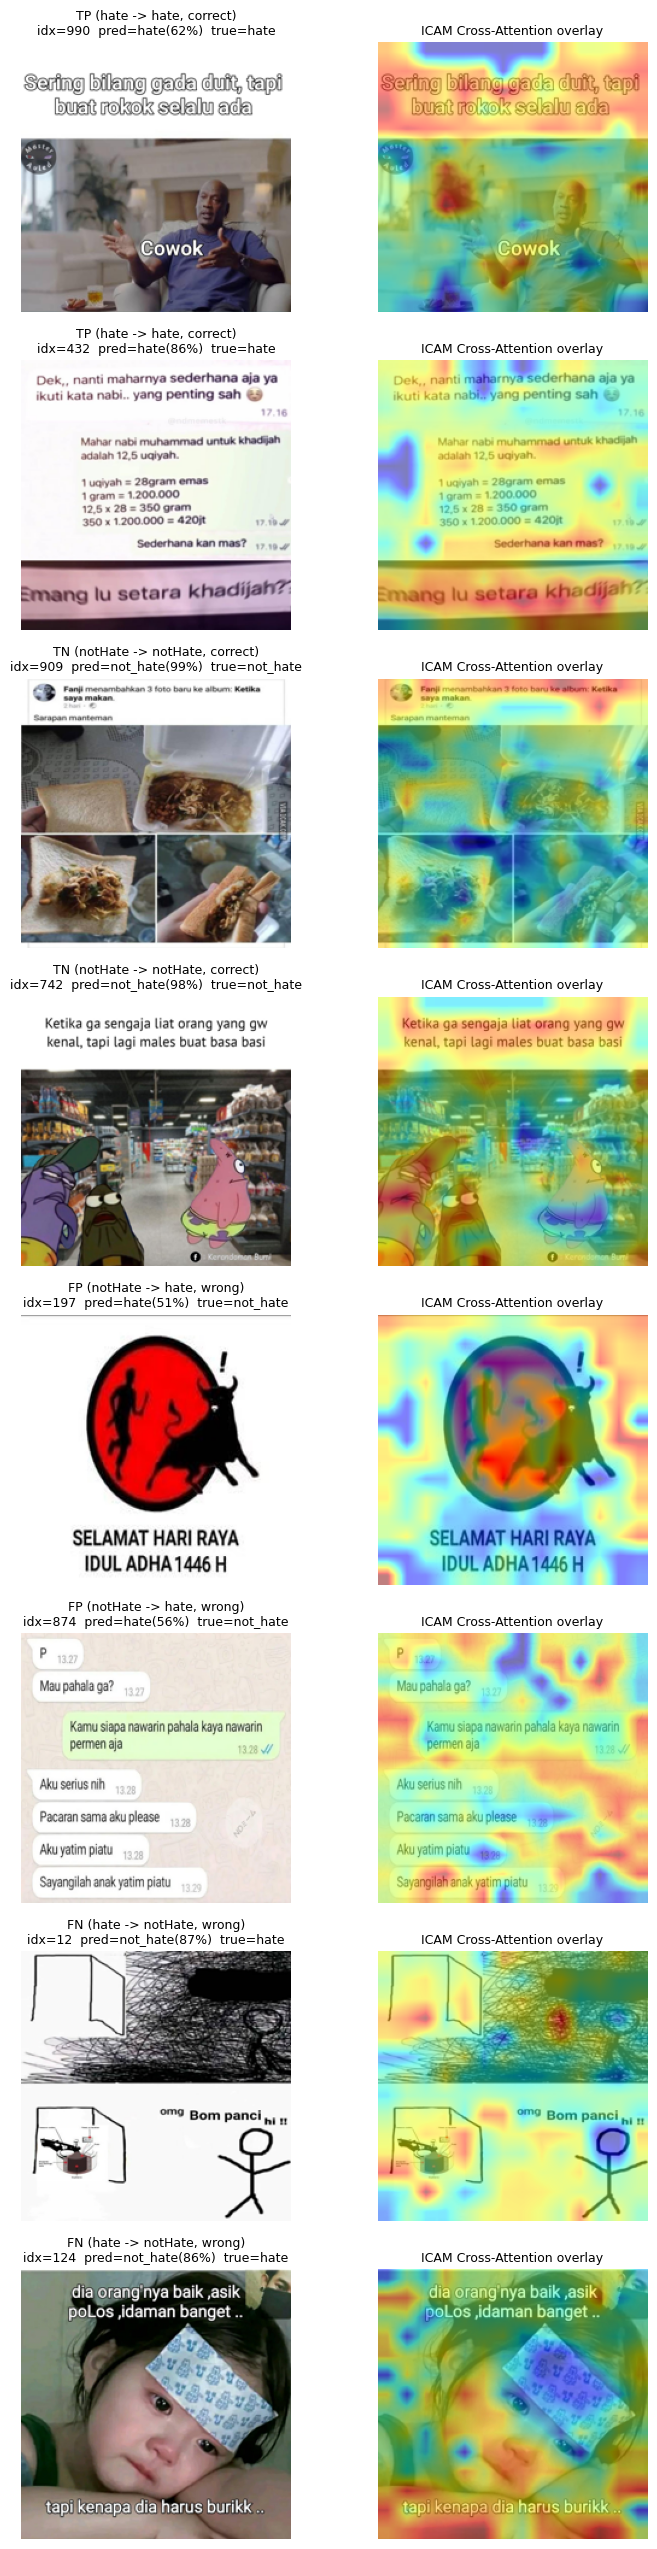


Saved viz: /kaggle/working/xai_2A2_cross_attention/cross_attn_visualizations.png


In [16]:
mask_tp = (all_preds == 1) & (all_labels == 1)
mask_tn = (all_preds == 0) & (all_labels == 0)
mask_fp = (all_preds == 1) & (all_labels == 0)
mask_fn = (all_preds == 0) & (all_labels == 1)

def pick_indices(mask, k, seed=0):
    pool = np.where(mask)[0]
    return np.random.RandomState(seed).choice(pool, size=min(k, len(pool)), replace=False)

picks = {
    "TP (hate -> hate, correct)":         pick_indices(mask_tp, 2),
    "TN (notHate -> notHate, correct)":   pick_indices(mask_tn, 2),
    "FP (notHate -> hate, wrong)":        pick_indices(mask_fp, 2),
    "FN (hate -> notHate, wrong)":        pick_indices(mask_fn, 2),
}

n_total = sum(len(v) for v in picks.values())
fig, axes = plt.subplots(n_total, 2, figsize=(8, 3.2*n_total))
if n_total == 1: axes = axes.reshape(1, 2)

row = 0
for cat, idx_list in picks.items():
    for i in idx_list:
        idx_global = int(all_idxs[i])
        img_path   = all_paths[i]
        pred_str   = "hate" if all_preds[i] == 1 else "not_hate"
        true_str   = "hate" if all_labels[i] == 1 else "not_hate"
        prob_pct   = all_probs[i] * 100

        img_pil = Image.open(img_path).convert("RGB")
        blended, attn_norm = overlay_attention(img_pil, all_maps[i], alpha=0.5)

        axes[row, 0].imshow(img_pil.resize((CONFIG["img_size"], CONFIG["img_size"])))
        axes[row, 0].set_title(f"{cat}\nidx={idx_global}  pred={pred_str}({prob_pct:.0f}%)  true={true_str}",
                                fontsize=9)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(blended)
        axes[row, 1].set_title("ICAM Cross-Attention overlay", fontsize=9)
        axes[row, 1].axis("off")
        row += 1

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cross_attn_visualizations.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"\nSaved viz: {OUTPUT_DIR / 'cross_attn_visualizations.png'}")

## CELL 17 — Top Patches Analysis

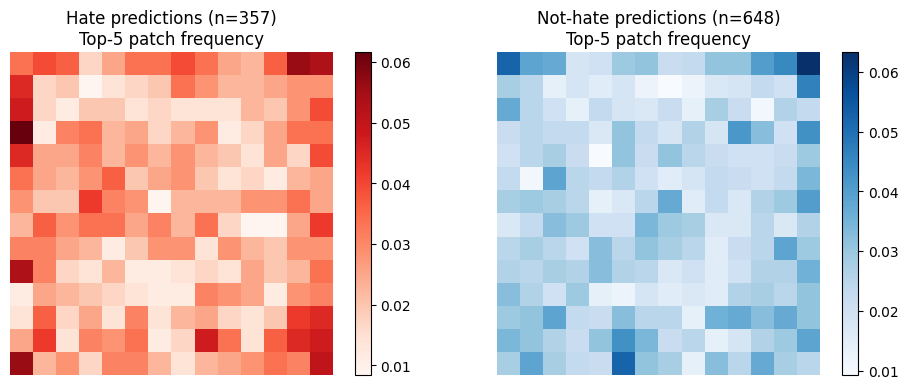


Mean top-5 patch frequency:
  hate     : center of mass = (6.46, 6.54)
  not_hate : center of mass = (6.62, 6.60)


In [17]:
# Untuk tiap sampel: ambil koordinat top-5 patch
top_patches = []
for i in range(len(all_maps)):
    flat_i = all_maps[i].flatten()
    top_idx = np.argsort(-flat_i)[:5]
    coords = [(int(p // 14), int(p % 14), float(flat_i[p])) for p in top_idx]
    top_patches.append(coords)

# Aggregate: di pixel mana saja hate vs not-hate paling sering attended?
hate_heatmap     = np.zeros((14, 14), dtype=np.float32)
not_hate_heatmap = np.zeros((14, 14), dtype=np.float32)

for i, coords in enumerate(top_patches):
    bag = hate_heatmap if all_preds[i] == 1 else not_hate_heatmap
    for r, c, _ in coords:
        bag[r, c] += 1

n_hate     = int((all_preds == 1).sum())
n_not_hate = int((all_preds == 0).sum())

if n_hate > 0:     hate_heatmap     /= n_hate
if n_not_hate > 0: not_hate_heatmap /= n_not_hate

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].imshow(hate_heatmap, cmap="Reds")
axes[0].set_title(f"Hate predictions (n={n_hate})\nTop-5 patch frequency")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(not_hate_heatmap, cmap="Blues")
axes[1].set_title(f"Not-hate predictions (n={n_not_hate})\nTop-5 patch frequency")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_patches_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"\nMean top-5 patch frequency:")
print(f"  hate     : center of mass = ({(hate_heatmap * np.arange(14)[:,None]).sum() / hate_heatmap.sum():.2f}, "
      f"{(hate_heatmap * np.arange(14)[None,:]).sum() / hate_heatmap.sum():.2f})")
print(f"  not_hate : center of mass = ({(not_hate_heatmap * np.arange(14)[:,None]).sum() / not_hate_heatmap.sum():.2f}, "
      f"{(not_hate_heatmap * np.arange(14)[None,:]).sum() / not_hate_heatmap.sum():.2f})")

## CELL 18 — Save Top Patches Analysis

In [18]:
analysis = {
    "config": {"top_k_patches": 5},
    "per_sample_top_patches": [
        {
            "idx":         int(all_idxs[i]),
            "pred_class":  int(all_preds[i]),
            "true_label":  int(all_labels[i]),
            "pred_prob":   float(all_probs[i]),
            "top5_patches": [
                {"row": int(r), "col": int(c), "score": float(s)}
                for (r, c, s) in top_patches[i]
            ],
        }
        for i in range(len(all_maps))
    ],
    "aggregate_hate_top5_freq":     hate_heatmap.tolist(),
    "aggregate_nothate_top5_freq":  not_hate_heatmap.tolist(),
}
with open(OUTPUT_DIR / "cross_attn_top_patches.json", "w") as f:
    json.dump(analysis, f)
print(f"Saved: cross_attn_top_patches.json")

Saved: cross_attn_top_patches.json


## CELL 19 — Summary

In [19]:
final_summary = {
    "exp_id":     CONFIG["exp_id"],
    "ckpt_path":  str(CKPT_PATH),
    "n_samples":  int(len(all_maps)),
    "test_accuracy": float((all_preds == all_labels).mean()),
    "elapsed_min":   float(elapsed / 60),
    "map_stats": {
        "shape":          list(all_maps.shape),
        "mean":           float(all_maps.mean()),
        "std":            float(all_maps.std()),
        "top10_share":    float(top10_share.mean()),
        "top20_share":    float(top20_share.mean()),
    },
    "outputs": {
        "cross_attn_maps.npz":         "shape (n, 14, 14)",
        "image_paths.json":            "idx -> image path",
        "cross_attn_top_patches.json": "top-5 patch coords per sample + aggregate",
        "cross_attn_visualizations.png": "8 sample overlay (TP/TN/FP/FN)",
        "top_patches_heatmap.png":     "aggregate top-5 patch frequency hate vs not-hate",
    },
}

with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2, default=str)
with open(OUTPUT_DIR / "final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2)

print(f"\n{'='*72}\nKOMPONEN 2 (CROSS-ATTENTION) DONE\n{'='*72}")
print(f"Experiment        : {CONFIG['exp_id']}")
print(f"Samples processed : {len(all_maps)}")
print(f"Test accuracy     : {(all_preds == all_labels).mean():.4f}")
print(f"Map shape         : {all_maps.shape}")
print(f"Top-10 share      : {top10_share.mean()*100:.1f}%  (uniform={10/196*100:.1f}%)")
print(f"Top-20 share      : {top20_share.mean()*100:.1f}%  (uniform={20/196*100:.1f}%)")
print(f"Elapsed           : {elapsed/60:.1f} min")
print(f"\nArtifacts saved to: {OUTPUT_DIR}")


KOMPONEN 2 (CROSS-ATTENTION) DONE
Experiment        : 2A.2_cross_attention_map
Samples processed : 1005
Test accuracy     : 0.8149
Map shape         : (1005, 14, 14)
Top-10 share      : 5.2%  (uniform=5.1%)
Top-20 share      : 10.3%  (uniform=10.2%)
Elapsed           : 0.4 min

Artifacts saved to: /kaggle/working/xai_2A2_cross_attention
